# The model that learned nothing and scored 91%

Everything in machine learning rests on one question: does the model work on data
it has not seen? This notebook shows three ways to get a misleading answer. The
first is a model that fits the training data perfectly and is bad at prediction.
The second is a classifier that scores 91% on data that contains no information at
all, because one step of the analysis peeked at the test set. The third is a model
that is 95% accurate and misses most of the cases we care about.

## 1. A perfect fit that predicts badly

We generate 600 points in two classes whose boundary is curved and noisy, keep half
of them for testing, and fit $k$ nearest neighbors for many values of $k$. Watch the
two curves: the error on the training points and the error on the test points.

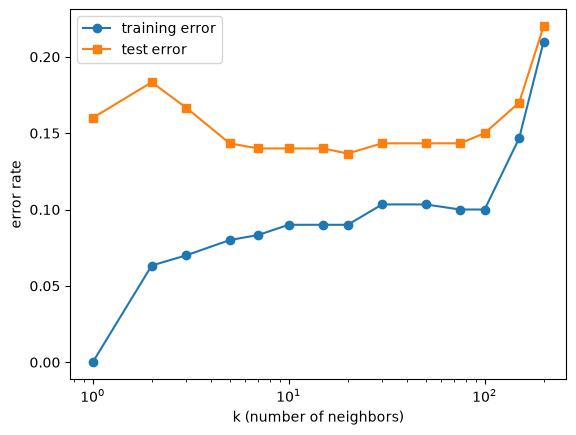

k =   1   training error 0.00   test error 0.16
k =   2   training error 0.06   test error 0.18
k =   3   training error 0.07   test error 0.17
k =   5   training error 0.08   test error 0.14
k =   7   training error 0.08   test error 0.14
k =  10   training error 0.09   test error 0.14
k =  15   training error 0.09   test error 0.14
k =  20   training error 0.09   test error 0.14
k =  30   training error 0.10   test error 0.14
k =  50   training error 0.10   test error 0.14
k =  75   training error 0.10   test error 0.14
k = 100   training error 0.10   test error 0.15
k = 150   training error 0.15   test error 0.17
k = 200   training error 0.21   test error 0.22


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = make_moons(n_samples=600, noise=0.35, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=0)

ks = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200]
train_err, test_err = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    train_err.append(1 - model.score(X_train, y_train))
    test_err.append(1 - model.score(X_test, y_test))

plt.semilogx(ks, train_err, "o-", label="training error")
plt.semilogx(ks, test_err, "s-", label="test error")
plt.xlabel("k (number of neighbors)"); plt.ylabel("error rate"); plt.legend(); plt.show()
for k, a, b in zip(ks, train_err, test_err):
    print(f"k = {k:>3}   training error {a:.2f}   test error {b:.2f}")

With $k = 1$ the training error is exactly zero: every point is its own nearest
neighbor, so the model reproduces the training set perfectly, and yet its test
error is clearly higher than for $k$ between 5 and 100. As $k$ grows, the training
error rises and the test error falls, and both stay flat over a wide range; for the
largest values both rise again, because the model averages over so many neighbors
that it can no longer follow the curved boundary. Only the test error tells you which model to use. The training
error, the number you would see if you did not split the data, points you to the
worst model.

## 2. Ninety-one percent on pure noise

Now the data has no information at all: 100 respondents, 5 000 features drawn at
random, and a label tossed by a coin. No model can do better than 50% on new data.

A common analysis first selects the features most correlated with the label and
then cross-validates a classifier on the selected features. We do exactly that, with
the selection computed on the whole dataset.

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(1)
n, p = 100, 5000
X_noise = rng.normal(size=(n, p))
y_noise = rng.integers(0, 2, size=n)          # a coin toss, unrelated to X

top20 = SelectKBest(f_classif, k=20).fit(X_noise, y_noise).get_support()   # selected on ALL the data
leaky = cross_val_score(LogisticRegression(), X_noise[:, top20], y_noise, cv=5)
print(f"selection outside cross-validation: accuracy {leaky.mean():.2f}")

honest = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())   # selection inside each fold
clean = cross_val_score(honest, X_noise, y_noise, cv=5)
print(f"selection inside cross-validation:  accuracy {clean.mean():.2f}")

selection outside cross-validation: accuracy 0.91
selection inside cross-validation:  accuracy 0.47


The first number is far above chance, and it is a fiction. Among 5 000 random
features, a few happen to correlate with the coin tosses of these 100 people; the
selection step found them by looking at all 100 labels, including the ones that
were later used for testing. The classifier then "predicts" test labels that the
feature selection had already seen. This is information leakage: nothing was
learned, and the test set was not really unseen. The pipeline version repeats the
selection inside every training fold, the test fold never influences it, and the
accuracy drops to chance, which is the truth. Every step that uses the labels,
including feature selection, scaling with the labels, and choosing hyperparameters,
has to happen inside the training data only.

## 3. Ninety-five percent accurate, and mostly blind

The last trap is accuracy on an imbalanced problem. We build a task where about 6% of the
cases are positive, the ones we want to find, and train a logistic regression.

In [3]:
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X_imb, y_imb = make_classification(n_samples=4000, n_features=10, n_informative=3,
                                   weights=[0.95, 0.05], flip_y=0.02, random_state=2)
Xa, Xb, ya, yb = train_test_split(X_imb, y_imb, test_size=0.5, random_state=0)
model = LogisticRegression().fit(Xa, ya)
always_negative = DummyClassifier(strategy="most_frequent").fit(Xa, ya)

def report(name, pred):
    print(f"{name:<32} accuracy {accuracy_score(yb, pred):.3f}   precision {precision_score(yb, pred, zero_division=0):.2f}"
          f"   recall {recall_score(yb, pred):.2f}   F1 {f1_score(yb, pred):.2f}")

report("always predict negative", always_negative.predict(Xb))
report("logistic regression, threshold 0.5", model.predict(Xb))
prob = model.predict_proba(Xb)[:, 1]
report("logistic regression, threshold 0.15", (prob > 0.15).astype(int))

always predict negative          accuracy 0.938   precision 0.00   recall 0.00   F1 0.00
logistic regression, threshold 0.5 accuracy 0.952   precision 0.84   recall 0.29   F1 0.43
logistic regression, threshold 0.15 accuracy 0.926   precision 0.43   recall 0.56   F1 0.49


The classifier that never says "positive" is about 94% accurate, because 94% of
the cases are negative. The trained model has almost the same accuracy and, at the
default threshold, finds only a fraction of the positives. Lowering the threshold
catches many more of them at the cost of precision, with a barely changed accuracy.
Accuracy cannot see any of this; precision, recall and $F_1$ on the positive class
can, and which of them to optimize depends on what a missed case and a false alarm
cost in your application.

**What we used:** [the train/test split](../Transcripts/10-MachineLearning.md#6-generalization-the-traintest-split),
[k nearest neighbors](../Transcripts/10-MachineLearning.md#7-a-first-model-k-nearest-neighbors),
[overfitting and underfitting](../Transcripts/10-MachineLearning.md#8-overfitting-underfitting-bias-and-variance),
[error, loss and the traps of accuracy](../Transcripts/10-MachineLearning.md#5-error-loss-and-the-traps-of-accuracy)
and [features](../Transcripts/10-MachineLearning.md#4-features) from session 10.